# Course: Computer Vision and Pattern Recognition (CVPR)
## Assignment 1 — Fashion Product Classification

**Student Name:** MD Sabbir Hasan  
**Student ID:** 23-51098-1  
**Dataset:** Fashion-MNIST (Mendeley Data)  
**Framework:** PyTorch  

### Objective
Build a basic CNN from scratch to classify ten kinds of clothing, footwear, and accessories. Choose the checkpoint on validation data, then evaluate it on the official test split.

## 1. Import Libraries

In [1]:
from pathlib import Path
from hashlib import sha256
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from IPython.display import Markdown, display

if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
    torch.set_num_threads(6)

torch.manual_seed(23)
print('Device:', device)

Matplotlib is building the font cache; this may take a moment.


Device: mps


## 2. Load and Explore Dataset

Fashion-MNIST contains 70,000 grayscale images, each 28 × 28 pixels, and ten classes. Similar outlines can make shirts, pullovers and coats difficult to distinguish.

**Source:** Robert O'Shea, [fp_datasets, Mendeley Data V2](https://data.mendeley.com/datasets/fb7xddyxs4/2), DOI 10.17632/fb7xddyxs4.2. Use the FashionMNIST_data.npz file (45.47 MB). The original dataset is by [Zalando Research](https://github.com/zalandoresearch/fashion-mnist).

The official train pool contains 60,000 images. We use 54,000 for training and 6,000 for validation. The official test split has 10,000 images. The archive stores flattened images and one-hot labels.

If the runtime cannot download the archive, download FashionMNIST_data.npz from the linked record and place it in the notebook's working directory. The notebook verifies the same checksum in both cases.

In [2]:
archive = Path('FashionMNIST_data.npz')
url = (
    'https://data.mendeley.com/public-files/datasets/fb7xddyxs4/'
    'files/78d02cf8-3f3f-4e71-9e45-169865d3a7ed/file_downloaded'
)
expected_hash = '54a4bf2cf27fc7e7e1a575da5f3fae455c8f58da2a31da94c9f1560379d23112'
if not archive.exists():
    temporary_file = archive.with_suffix('.part')
    urlretrieve(url, temporary_file)
    if sha256(temporary_file.read_bytes()).hexdigest() != expected_hash:
        raise ValueError('The download does not match the Mendeley archive.')
    temporary_file.replace(archive)
if sha256(archive.read_bytes()).hexdigest() != expected_hash:
    raise ValueError('Replace the archive with the original Mendeley file.')

with np.load(archive) as data:
    all_images = torch.from_numpy(data['X_trainval']).float().reshape(-1, 1, 28, 28)
    all_labels = torch.from_numpy(data['Y_trainval'].argmax(axis=1)).long()
    test_images = torch.from_numpy(data['X_test']).float().reshape(-1, 1, 28, 28)
    test_labels = torch.from_numpy(data['Y_test'].argmax(axis=1)).long()

assert len(all_images) == len(all_labels) == 60000
assert len(test_images) == len(test_labels) == 10000
assert len(all_labels.unique()) == len(test_labels.unique()) == 10

shuffled = torch.randperm(len(all_images))
val_indices, train_indices = shuffled[:6000], shuffled[6000:]
train_images, train_labels = all_images[train_indices], all_labels[train_indices]
val_images, val_labels = all_images[val_indices], all_labels[val_indices]
del all_images, all_labels

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print('Archive size (MB):', round(archive.stat().st_size / 1e6, 2))
print('Train:', tuple(train_images.shape))
print('Validation:', tuple(val_images.shape))
print('Test:', tuple(test_images.shape))

Archive size (MB): 45.47
Train: (54000, 1, 28, 28)
Validation: (6000, 1, 28, 28)
Test: (10000, 1, 28, 28)


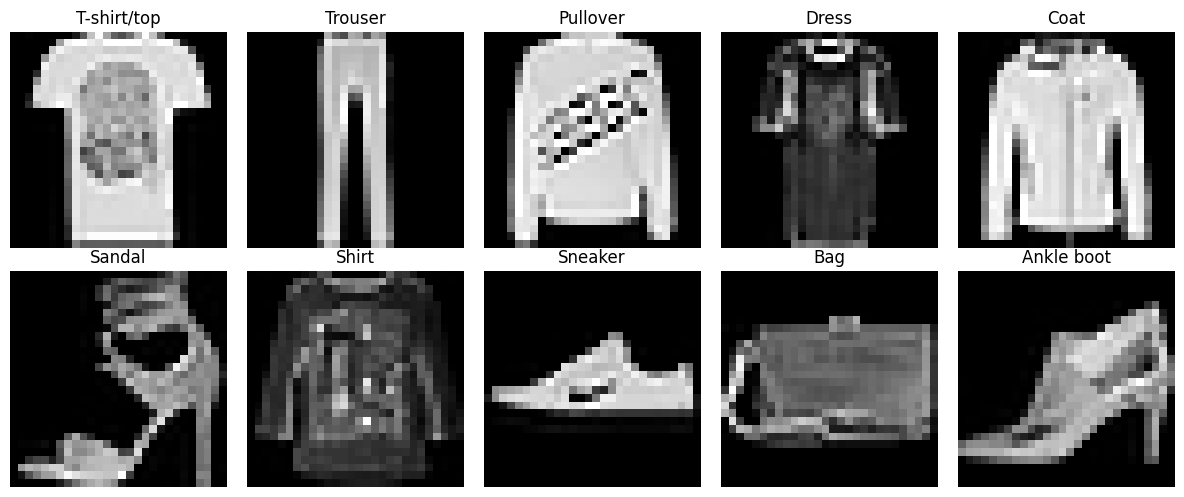

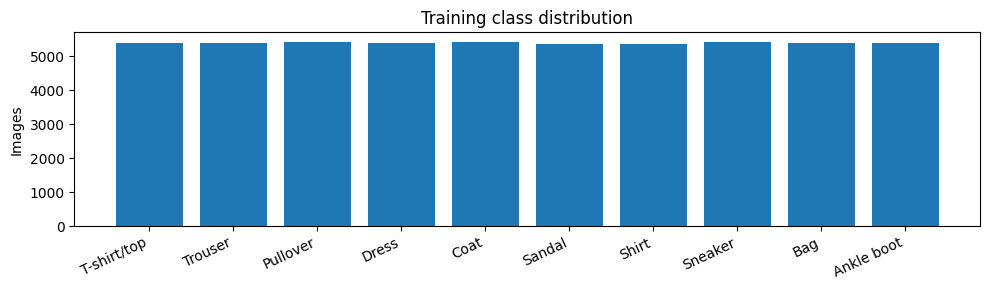

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for label, ax in enumerate(axes.flat):
    first = (train_labels == label).nonzero()[0].item()
    ax.imshow(train_images[first, 0], cmap='gray')
    ax.set_title(class_names[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3))
plt.bar(class_names, torch.bincount(train_labels, minlength=10).numpy())
plt.xticks(rotation=25, ha='right')
plt.ylabel('Images')
plt.title('Training class distribution')
plt.tight_layout()
plt.show()

## 3. Data Preprocessing and Augmentation

Normalize using the training images' mean and standard deviation. During training, randomly flip images horizontally with one random choice per batch. Validation and testing use the original orientation. The archive's grayscale pixels are already scaled to [0, 1].

In [4]:
mean, std = train_images.mean().item(), train_images.std().item()
batch_size = 256
epoch_count = 8
learning_rate = 0.001

train_loader = DataLoader(TensorDataset(train_images, train_labels), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(val_images, val_labels), batch_size=512)
test_loader = DataLoader(TensorDataset(test_images, test_labels), batch_size=512)

def prepare(images, labels, augment=False):
    images = images.to(device)
    if augment and torch.rand(1).item() < 0.5:
        images = images.flip(dims=[3])
    return (images - mean) / std, labels.to(device)

print('Training mean and standard deviation:', round(mean, 4), round(std, 4))

Training mean and standard deviation: 0.2861 0.3531


## 4. Define CNN Architecture

Three 3 × 3 convolution layers learn shapes and textures. The first two max pools shrink the spatial dimensions from 28 to 14 to 7. A 3 × 3 average pool reduces the last map to 2 × 2. The 128-unit classifier uses dropout and returns ten logits. Batch normalization is applied before each convolution block's ReLU.

In [5]:
model = nn.Sequential(
    nn.Conv2d(1, 24, kernel_size=3, padding=1),
    nn.BatchNorm2d(24),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(24, 48, kernel_size=3, padding=1),
    nn.BatchNorm2d(48),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(48, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.AvgPool2d(3),

    nn.Flatten(),
    nn.Linear(64 * 2 * 2, 128),
    nn.ReLU(),
    nn.Dropout(0.25),
    nn.Linear(128, 10)
).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=1
)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

Sequential(
  (0): Conv2d(1, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(24, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(48, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): AvgPool2d(kernel_size=3, stride=3, padding=0)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=256, out_features=128, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.25, inplace=False)
  (16): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 72826


## 5. Training Loop with Validation

Adam updates weights only on training batches. The scheduler monitors validation loss. A checkpoint is saved when validation accuracy improves. Training accuracy is measured with augmentation enabled. Validation and test predictions use evaluation mode with gradients disabled.

In [6]:
def train_epoch():
    model.train()
    losses, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = prepare(images, labels, augment=True)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

        count = labels.size(0)
        losses += loss.item() * count
        correct += (logits.argmax(1) == labels).sum().item()
        total += count
    return losses / total, correct / total

@torch.no_grad()
def evaluate(loader):
    model.eval()
    losses = 0.0
    predictions, answers = [], []
    for images, labels in loader:
        images, labels = prepare(images, labels)
        logits = model(images)
        losses += loss_fn(logits, labels).item() * labels.size(0)
        predictions.extend(logits.argmax(1).cpu().tolist())
        answers.extend(labels.cpu().tolist())
    predictions, answers = np.array(predictions), np.array(answers)
    return losses / len(answers), np.mean(predictions == answers), predictions, answers

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []
best_accuracy = -1
checkpoint = Path('fashion_cnn_23-51098-1.pth')

for epoch in range(1, epoch_count + 1):
    train_loss, train_accuracy = train_epoch()
    val_loss, val_accuracy, _, _ = evaluate(val_loader)
    scheduler.step(val_loss)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_epoch = epoch
        torch.save(model.state_dict(), checkpoint)
    print(f'Epoch {epoch:02d} | train loss {train_loss:.4f} | train accuracy {train_accuracy:.2%} | '
          f'validation loss {val_loss:.4f} | validation accuracy {val_accuracy:.2%}', flush=True)

model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
print(f'Selected epoch {best_epoch}, validation accuracy {best_accuracy:.2%}.')

Epoch 01 | train loss 0.6825 | train accuracy 76.79% | validation loss 0.3928 | validation accuracy 85.78%


Epoch 02 | train loss 0.3752 | train accuracy 86.53% | validation loss 0.3204 | validation accuracy 88.20%


Epoch 03 | train loss 0.3286 | train accuracy 88.31% | validation loss 0.3179 | validation accuracy 88.12%


Epoch 04 | train loss 0.2957 | train accuracy 89.41% | validation loss 0.2743 | validation accuracy 90.00%


Epoch 05 | train loss 0.2752 | train accuracy 90.00% | validation loss 0.2751 | validation accuracy 89.78%


Epoch 06 | train loss 0.2578 | train accuracy 90.67% | validation loss 0.3004 | validation accuracy 89.12%


Epoch 07 | train loss 0.2319 | train accuracy 91.57% | validation loss 0.2311 | validation accuracy 91.58%


Epoch 08 | train loss 0.2209 | train accuracy 92.09% | validation loss 0.2266 | validation accuracy 91.58%


Selected epoch 7, validation accuracy 91.58%.


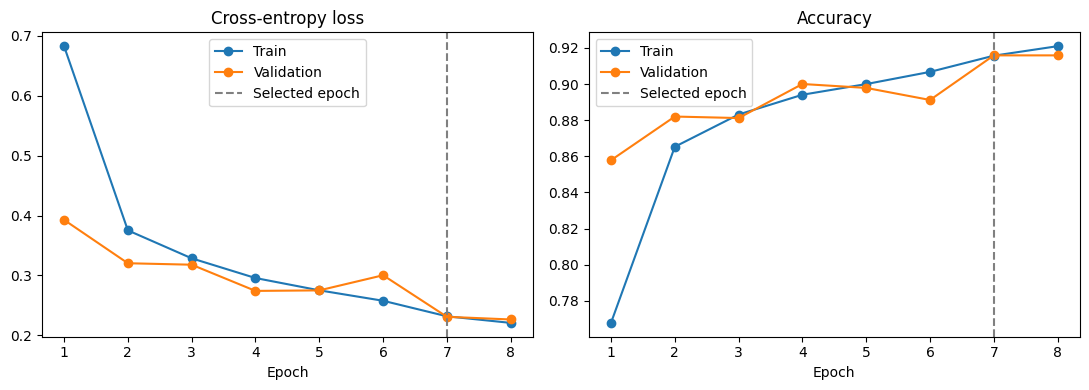

In [7]:
epochs = range(1, epoch_count + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, train_losses, 'o-', label='Train')
axes[0].plot(epochs, val_losses, 'o-', label='Validation')
axes[0].set_title('Cross-entropy loss')
axes[1].plot(epochs, train_accuracies, 'o-', label='Train')
axes[1].plot(epochs, val_accuracies, 'o-', label='Validation')
axes[1].set_title('Accuracy')
for ax in axes:
    ax.axvline(best_epoch, color='gray', ls='--', label='Selected epoch')
    ax.set_xlabel('Epoch')
    ax.set_xticks(list(epochs))
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Evaluate Model on Test Set

Evaluate the selected checkpoint on the official test split. Report accuracy, cross-entropy loss, and per-class precision, recall and F1.

In [8]:
test_loss, test_accuracy, predictions, answers = evaluate(test_loader)
labels = np.arange(len(class_names))
precision, recall, f1, support = precision_recall_fscore_support(
    answers, predictions, labels=labels, zero_division=0
)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    answers, predictions, average='macro', zero_division=0
)

print(f'Test accuracy: {test_accuracy:.2%}')
print(f'Test loss: {test_loss:.6f}')
print(f'Macro precision: {macro_p:.2%} | macro recall: {macro_r:.2%} | macro F1: {macro_f1:.2%}')
print(f'Weighted F1: {np.average(f1, weights=support):.2%}')
for i, name in enumerate(class_names):
    print(f'{name:<12} precision {precision[i]:.2%} | recall {recall[i]:.2%} | '
          f'F1 {f1[i]:.2%} | support {support[i]}')

Test accuracy: 90.15%
Test loss: 0.263416
Macro precision: 90.21% | macro recall: 90.15% | macro F1: 90.08%
Weighted F1: 90.08%
T-shirt/top  precision 80.91% | recall 90.30% | F1 85.35% | support 1000
Trouser      precision 98.02% | recall 98.90% | F1 98.46% | support 1000
Pullover     precision 81.35% | recall 90.70% | F1 85.77% | support 1000
Dress        precision 90.71% | recall 89.80% | F1 90.25% | support 1000
Coat         precision 87.22% | recall 79.20% | F1 83.02% | support 1000
Sandal       precision 97.96% | recall 95.80% | F1 96.87% | support 1000
Shirt        precision 77.49% | recall 68.50% | F1 72.72% | support 1000
Sneaker      precision 93.89% | recall 95.20% | F1 94.54% | support 1000
Bag          precision 99.59% | recall 96.20% | F1 97.86% | support 1000
Ankle boot   precision 95.00% | recall 96.90% | F1 95.94% | support 1000


## 7. Visualizations and Error Analysis

A confusion matrix has true classes on its rows and predicted classes on its columns. A large off-diagonal value highlights a common error. Sample misclassifications below display the actual image, its label, and the model's prediction.

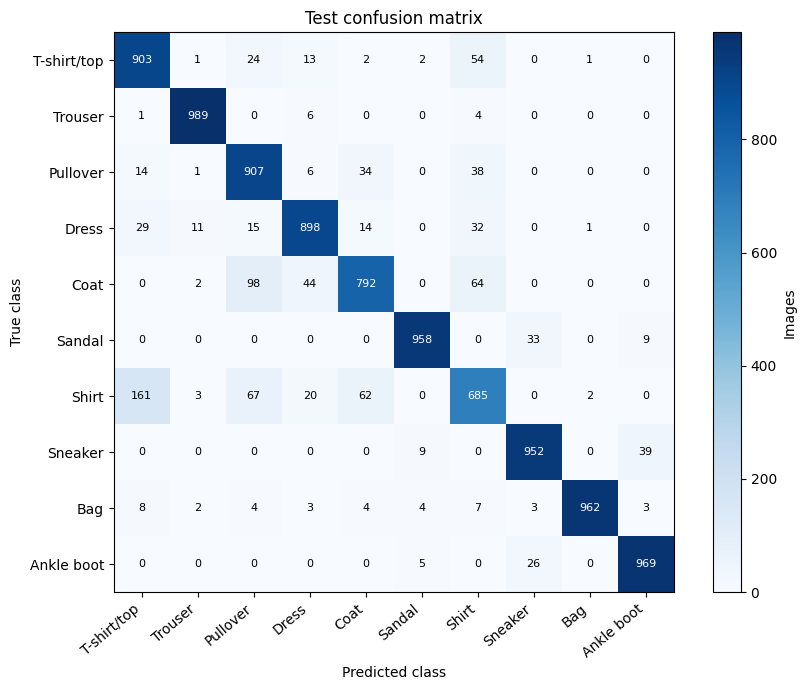

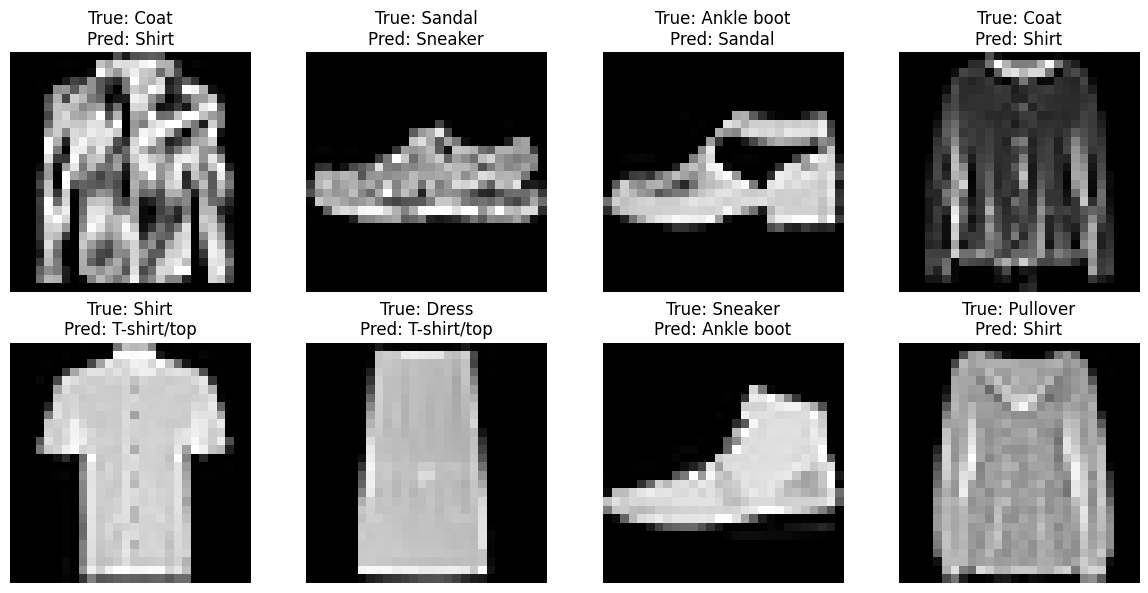

In [9]:
cm = confusion_matrix(answers, predictions, labels=labels)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm, cmap='Blues')
fig.colorbar(im, ax=ax, label='Images')
ax.set_xticks(labels, class_names, rotation=40, ha='right')
ax.set_yticks(labels, class_names)
ax.set(xlabel='Predicted class', ylabel='True class', title='Test confusion matrix')
for i in labels:
    for j in labels:
        color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i, cm[i, j], ha='center', va='center', color=color, fontsize=8)
plt.tight_layout()
plt.show()

wrong = np.flatnonzero(answers != predictions)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    ax.axis('off')
for ax, ix in zip(axes.flat, wrong[:8]):
    ax.imshow(test_images[ix, 0], cmap='gray')
    ax.set_title(f'True: {class_names[answers[ix]]}\nPred: {class_names[predictions[ix]]}')
plt.tight_layout()
plt.show()

## 8. Results and Discussion

In [10]:
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)
true_id, pred_id = np.unravel_index(mistakes.argmax(), mistakes.shape)
hardest = int(recall.argmin())
easiest = int(recall.argmax())
correct_count = int((answers == predictions).sum())
display(Markdown(f'''
- **Selected checkpoint:** epoch {best_epoch}, validation accuracy {best_accuracy:.2%}.
- **Test result:** {correct_count:,} of {len(answers):,} correct ({test_accuracy:.2%}).
- **Lowest validation loss over training:** {min(val_losses):.6f}.
- **Highest recall:** {class_names[easiest]} ({recall[easiest]:.2%}).
- **Lowest recall:** {class_names[hardest]} ({recall[hardest]:.2%}).
- **Most frequent error:** {class_names[true_id]} predicted as {class_names[pred_id]} ({mistakes[true_id, pred_id]} images).

Similar silhouettes in 28 × 28 grayscale images can contribute to errors. This run measures one split and one seed.
'''))


- **Selected checkpoint:** epoch 7, validation accuracy 91.58%.
- **Test result:** 9,015 of 10,000 correct (90.15%).
- **Lowest validation loss over training:** 0.226598.
- **Highest recall:** Trouser (98.90%).
- **Lowest recall:** Shirt (68.50%).
- **Most frequent error:** Shirt predicted as T-shirt/top (161 images).

Similar silhouettes in 28 × 28 grayscale images can contribute to errors. This run measures one split and one seed.


## 9. Conclusions and Future Work

The notebook uses a custom CNN to recognize fashion-product classes. Check the per-class recall and confusion matrix alongside overall accuracy. Future work could compare augmentation choices on validation data and repeat the experiment with different seeds. The training cell saves the validation-selected model weights to the runtime.